### 01. Пороговый анализ: где начинается вред? 
С какого момента время, проведенное в социальных сетях и время просмотра сериалов начинают вредить оценкам? Есть ли точка перелома, после которой результат экзамена резко падает? Одинакова ли эта точка для соцсетей и Netflix?

In [1]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

from src.preparation import load_df
df = load_df()

,mean_score_social_media,mean_score_netflix
hours,,
very low,73.618,73.943
low,71.689,71.194
moderate,69.511,69.003
high,66.812,67.640
very high,65.887,65.768


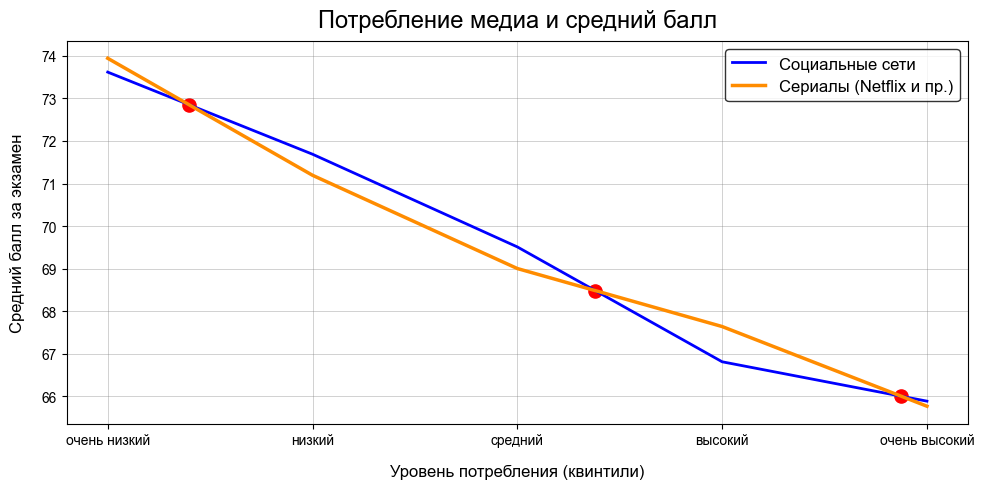

In [ ]:
import pandas as pd 
import matplotlib.pyplot as plt 
import src.constants as cnst 

plt.rcParams['font.family'] = 'Arial'

df_02_01 = df[['social_media_hours', 'netflix_hours', 'exam_score']]

labels = ['very low', 'low', 'moderate', 'high', 'very high']

df_02_01['social_media_grp'] = pd.qcut(df.social_media_hours, q=5, labels=labels)
df_02_01['netflix_grp'] = pd.qcut(df.netflix_hours, q=5, labels=labels)

social_media_grp = df_02_01.groupby('social_media_grp').exam_score.mean().round(3).to_frame().rename(columns={'exam_score': 'mean_score_social_media'})
netflix_grp = df_02_01.groupby('netflix_grp').exam_score.mean().round(3).to_frame().rename(columns={'exam_score': 'mean_score_netflix'})

res = pd.concat([social_media_grp, netflix_grp], axis=1, join='outer')
res['diff'] = res.mean_score_social_media - res.mean_score_netflix
res.index.name = 'hours'

display(res[['mean_score_social_media', 'mean_score_netflix']])


fix, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    res.index, res.mean_score_social_media, 
    color='blue', lw=2, 
    label='Социальные сети'
)

ax.plot(
    res.index, res.mean_score_netflix, 
    color='darkorange', lw=2.5, 
    label='Сериалы (Netflix и пр.)'
)

for i, d in enumerate(res['diff'][:-1]): 
    if d * res['diff'].to_list()[i + 1] < 0:
        t = abs(d) / (abs(d) + abs(res['diff'].to_list()[i + 1]))
        x_cross = i + t
        y_cross = res.mean_score_netflix.to_list()[i] + t * (res.mean_score_netflix.to_list()[i + 1] - res.mean_score_netflix.to_list()[i])
        ax.scatter(
            x_cross, y_cross, 
            color='red', s=90
            )
        
ax.grid(**cnst.GRID_PARAMS)
ax.legend(**cnst.LEGEND_PARAMS)

ax.set_xticks(range(5))
ax.set_xticklabels(['очень низкий', 'низкий', 'средний', 'высокий', 'очень высокий'])

ax.set_xlabel('Уровень потребления (квинтили)', **cnst.LABEL_PARAMS)
ax.set_ylabel('Средний балл за экзамен', **cnst.LABEL_PARAMS)
ax.set_title('Потребление медиа и средний балл', **cnst.TITLE_PARAMS)

plt.tight_layout()

#### 01. Выводы 

Проанализирована связь между потреблением медиа (соцсети и сериалы) и средним баллом за экзамен. Данные разбиты на 5 квинтилей по часам потребления — от «очень низкого» до «очень высокого».

***Результат:*** обе кривые показывают устойчивое снижение среднего балла с ростом потребления. Разница между крайними группами — около 7.7 балла у соцсетей (73.6 → 65.9) и 8.2 балла у сериалов (73.9 → 65.8).

***Ключевое наблюдение:*** линии практически совпадают по всей длине — расхождение не превышает 0.9 балла, а три точки пересечения указывают на то, что различия лежат в пределах шума. Тип досуга (соцсети / сериалы) не имеет значения — значим только объём затраченного времени.

***NB!*** Анализировалась корреляция, а не о причинность. Возможна обратная связь — студенты с низкой успеваемостью проводят больше времени в медиа. Для проверки нужен дополнительный анализ (например, контроль по исходному уровню подготовки).